In [2]:
import numpy as np
import math 
import matplotlib.pyplot as plt
import pandas as pd
import scipy.optimize as scpo


class UDS:
    def __init__(self,data_matrix):
        self.data = data_matrix

    @classmethod
    def data_excel(cls, file, rows, colums, sheet_nm = "Sheet1"):
        pd_file = pd.read_excel(file + ".xlsx",sheet_name=sheet_nm, usecols= colums)
        just_data = pd_file.iloc[rows[0]-2:rows[1]-1]
        fin_data = just_data.values.tolist()
        return cls(fin_data)
    
    @staticmethod
    def flatten(matrix):
        flat_list = []
        for row in matrix:
            flat_list.extend(row)
        return flat_list
    @staticmethod
    def sci_e_equal(num1,num2,round = 10):
        e_1 = 10**(int(math.log10(num1))-1)
        if e_1 < 0.0001:
            e_1_s = "{0}".format(e_1)
            e_1_s = e_1_s[1:]
            prop_num2 = "{0}".format((num2 * e_1**-1))
            return prop_num2 + e_1_s
        else:
            e_2 = -1*(int(math.log10(num2))-round) 
            e_2_f = ':.{0}'.format(e_2)
            e_2_f = '{' + e_2_f + 'f}'
            return e_2_f.format(num2)

    def getData(self):  #Return data matrix
        return self.data

    def functional_err(self, f, return_comp = False):
        comp_err = []
        orig_val = []
        for i in self.data:
            orig_val += [i[0]]
        fin_val = f(*orig_val)

        for i in range(len(self.data)):
            cur_val = orig_val.copy()
            cur_val[i] += self.data[i][1]
            comp_err += [abs(f(*cur_val) - fin_val)]

        fin_err = 0
        for i in comp_err:
            fin_err += i**2
        fin_err = (fin_err)**0.5
        
        if return_comp:
            return [[fin_val, fin_err], comp_err]
        return [fin_val, fin_err]
    
    def display_func_err(self, f, show_comp = False, **kwargs):
        fig = plt.figure(1) 
        fig.add_axes((0,0,0.75,0.10))
        ax = fig.gca()

        fx_name = "Z"
        fx_units = "n/a"
        comp_tbl_row = []  #The labels for the component table rows
        alphabet = ["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O","P","Q","R","S","T","U","V","W","x","Y","Z"]

        if 'f_name' in kwargs:
            fx_name = kwargs['f_name']
        if 'f_units' in kwargs:
            fx_units = kwargs['f_units']

        if show_comp:
            all_data = self.functional_err(f,return_comp= True)
            val_fin = all_data[0][0]
            err_fin = all_data[0][1]
            comp_err = all_data[1].copy()
            tbl_comp_err = []  #Holds the actual values to display in the component err table
            var_names = alphabet[:len(self.data)]
            if 'var_names' in kwargs:
                var_names = kwargs['var_names']
            for i in range(len(comp_err)):
                tbl_comp_err += [[comp_err[i]]]
                comp_tbl_row += ["$\\alpha_{0}^{{{1}}}$".format(fx_name,var_names[i])]

        else:
            all_data = self.functional_err(f,return_comp= False)
            val_fin = all_data[0]
            err_fin = all_data[1]


        # hide axes
        ax.axis('off')
        ax.axis('tight')
        axtl = r"{0}\ and\ its\ Error".format(fx_name)
        axtl = "$\\mathbfit{" + axtl + "}$"
        ax.set_title(axtl)
        fx_tbl_contents = [[val_fin,UDS.sci_e_equal(val_fin,err_fin)]]
        fx_tbl_headers = ["${0}$ (${1}$)".format(fx_name,fx_units), "$\\alpha_{0}$ (${1}$)".format(fx_name,fx_units)]

        fx_tbl = ax.table(cellText=fx_tbl_contents,cellLoc="center",colWidths= [0.5,0.5],colLabels=fx_tbl_headers, loc='center') #Table creation
        #setting the height of each cell
        for c in fx_tbl.get_celld().values():
            c.set_height(0.5)


        #### Code for error component tabel
        if show_comp:
            comp_tbl_headers = ["Component of total error (${0}$)".format(fx_units)]
            axis_height = 0.0578*len(comp_err) + 0.1424 #formula to calculate where to begin and the height of the axis based on the amount of component error

            fig.add_axes((0,-1*axis_height,0.75,axis_height))
            ax = fig.gca()
            ax.axis('off')
            ax.axis('tight')


            comp_tbl = ax.table(cellText=tbl_comp_err,cellLoc="center",colWidths=[0.5],colLabels=comp_tbl_headers,rowLabels=comp_tbl_row, loc='center')

            cell_height = 1/(2+len(comp_err))

            for c in comp_tbl.get_celld().values():
                c.set_height(cell_height)
        plt.show()


Lambda 1&2 Data alalysis and graphs

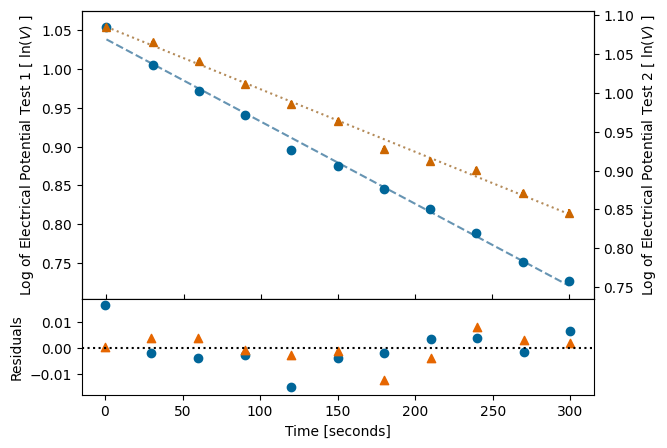

In [3]:
filename = "Lucas Coulomb's Law Working"
sheet_name = "Data"
l1_t = np.array(UDS.data_excel(filename,[3,13],"I:J",sheet_nm = sheet_name).getData())
l1_lnV = np.array(UDS.data_excel(filename,[3,13],"K:L",sheet_nm = sheet_name).getData())
l2_t = np.array(UDS.data_excel(filename,[3,13],"M:N",sheet_nm = sheet_name).getData())
l2_lnV = np.array(UDS.data_excel(filename,[3,13],"O:P",sheet_nm = sheet_name).getData())

def Line(x, gradient, intercept): 
    return gradient*x + intercept

fit_param_l1, co_matx_l1 = scpo.curve_fit(Line,l1_t[:,0],l1_lnV[:,0])
fit_param_l2, co_matx_l2 = scpo.curve_fit(Line,l2_t[:,0],l2_lnV[:,0])
l1_grad= fit_param_l1[0]
l1_int= fit_param_l1[1]
l2_grad= fit_param_l2[0]
l2_int= fit_param_l2[1]
l1_grad_err= np.sqrt(co_matx_l1[0,0])
l1_int_err= np.sqrt(co_matx_l1[1,1])
l2_grad_err= np.sqrt(co_matx_l2[0,0])
l2_int_err= np.sqrt(co_matx_l2[1,1])

l1_bfl = Line(l1_t[:,0],l1_grad,l1_int)
l2_bfl = Line(l2_t[:,0],l2_grad,l2_int)

#Residuals
l1_resid = l1_lnV[:,0] - l1_bfl
l2_resid = l2_lnV[:,0] - l2_bfl




#Figure Plotting
fig1 = plt.figure(1)
ax1 = fig1.add_axes((0.1,.3,.8,.6))
ax1.errorbar(l1_t[:,0],l1_lnV[:,0],yerr = l1_lnV[:,1],xerr=l1_t[:,1],fmt="o",color =(0,0.4,0.6))
ax1.plot(l1_t[:,0],l1_bfl, color = (0,0.3,0.5,0.6), ls = '--')

ax1.set_ylabel("Log of Electrical Potential Test $1$ [ ln($V)$ ]")
ax2 = ax1.twinx()
ax2.errorbar(l2_t[:,0],l2_lnV[:,0],yerr = l2_lnV[:,1],xerr=l2_t[:,1],fmt="^",color = (0.8,0.4,0))
ax2.plot(l2_t[:,0],l2_bfl, color = (0.55,0.3,0,0.65), ls = ':')
ax2.set_yticks(ax1.get_yticks())
view_lim = ax1.get_ylim()
data_diff = abs(l1_lnV[0,0]-l2_lnV[0,0])
view_lim_new = (view_lim[0]+data_diff,view_lim[1]+data_diff)
ax2.set_ylim(view_lim_new)
ax2.set_ylabel("Log of Electrical Potential Test $2$ [ ln($V)$ ]")
ax1.set_xticklabels([])
ax1.tick_params(axis="x",direction="in", pad=-22)


ax3 = fig1.add_axes((0.1,0.1,.8,0.2))
ax3.scatter(l1_t[:,0],l1_resid,color =(0,0.4,0.6))
ax3.scatter(l2_t[:,0],l2_resid,marker = '^',color = (0.9,0.4,0))
ax3.set_ylim((-0.018,0.019))
ax3.axhline(ls=":",color = 'black')
ax3.set_xlabel("Time [seconds]")
ax3.set_ylabel("Residuals")

#fig1.savefig("lambdaData.png",bbox_inches='tight')
plt.show()



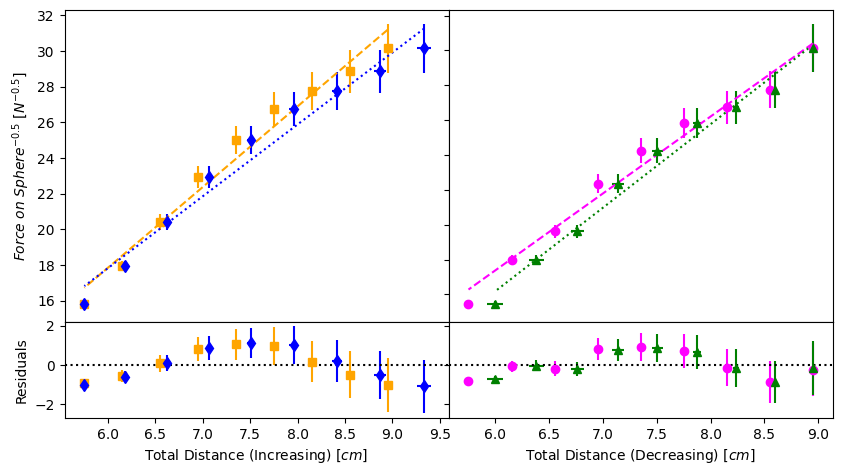

In [ ]:
filename = "Lucas Coulomb's Law Working"
sheet_name = "Data"
ds_f = np.array(UDS.data_excel(filename,[3,11],"A:B",sheet_nm = sheet_name).getData())
ds_s = np.array(UDS.data_excel(filename,[3,11],"C:D",sheet_nm = sheet_name).getData())
is_f = np.array(UDS.data_excel(filename,[3,11],"E:F",sheet_nm = sheet_name).getData())
is_s = np.array(UDS.data_excel(filename,[3,11],"G:H",sheet_nm = sheet_name).getData())
ds_charge = np.array(UDS.data_excel(filename,[13,13],"A:B",sheet_nm = sheet_name).getData())[0]
is_charge = np.array(UDS.data_excel(filename,[13,13],"E:F",sheet_nm = sheet_name).getData())[0]
d0 = np.array([0.0495,0.0001])
l1 = np.array([-1*l1_grad,l1_grad_err])
l2 = np.array([-1*l2_grad,l2_grad_err])
is_rho= np.array([0.0004, 8.482476053606048e-05])
ds_rho = np.array([-0.0004, 8.482476053606048e-05])

def tc(r,r0,l,rho):
    return r*np.exp(l*(r-r0)/(2*rho))

ds_r = []
is_r = []
ds_tcr = []
is_tcr = []
temp_data_arr = []
for i in range(len(ds_s)):
    ds_r += [[2*ds_s[i,0]+d0[0],np.sqrt((2*ds_s[i,1])**2 + (d0[1])**2)]]
    is_r += [[2*is_s[i,0]+d0[0],np.sqrt((2*is_s[i,1])**2 + (d0[1])**2)]]
for i in range(len(ds_s)):
    ds_dt_arr = [ds_r[i],ds_r[0],l1.tolist(),ds_rho.tolist()]  
    is_dt_arr = [is_r[i],is_r[-1],l1,is_rho]
    ds_tcr += [UDS(ds_dt_arr).functional_err(tc)]
    is_tcr += [UDS(is_dt_arr).functional_err(tc)]



ds_r = np.array(ds_r)*100 #Values multipled by 100 just for graphing purposes
is_r = np.array(is_r)*100
ds_tcr = np.array(ds_tcr)*100
is_tcr = np.array(is_tcr)*100


#BFL and Residuals
fit_param_ds, co_matx_ds = scpo.curve_fit(Line,ds_r[:,0],ds_f[:,0])
fit_param_is, co_matx_is = scpo.curve_fit(Line,is_r[:,0],is_f[:,0])
ds_grad= fit_param_ds[0]
ds_int= fit_param_ds[1]
is_grad= fit_param_is[0]
is_int= fit_param_is[1]

ds_grad_err= np.sqrt(co_matx_ds[0,0])
ds_int_err= np.sqrt(co_matx_ds[1,1])
is_grad_err= np.sqrt(co_matx_is[0,0])
is_int_err= np.sqrt(co_matx_is[1,1])

ds_bfl = Line(ds_r[:,0],ds_grad,ds_int)
is_bfl = Line(is_r[:,0],is_grad,is_int)

#Residuals
ds_resid = ds_f[:,0] - ds_bfl
is_resid = is_f[:,0] - is_bfl

#time correction
fit_param_dstc, co_matx_dstc = scpo.curve_fit(Line,ds_tcr[:,0],ds_f[:,0])
fit_param_istc, co_matx_istc = scpo.curve_fit(Line,is_tcr[:,0],is_f[:,0])
dstc_grad= fit_param_dstc[0]
dstc_int= fit_param_dstc[1]
istc_grad= fit_param_istc[0]
istc_int= fit_param_istc[1]
dstc_grad_err= np.sqrt(co_matx_dstc[0,0])
dstc_int_err= np.sqrt(co_matx_dstc[1,1])
istc_grad_err= np.sqrt(co_matx_istc[0,0])
istc_int_err= np.sqrt(co_matx_istc[1,1])

dstc_bfl = Line(ds_tcr[:,0],dstc_grad,dstc_int)
istc_bfl = Line(is_tcr[:,0],istc_grad,istc_int)

#Residuals
dstc_resid = ds_f[:,0] - dstc_bfl
istc_resid = is_f[:,0] - istc_bfl

#Plotting time

fig2 = plt.figure(2)
ax4 = fig2.add_axes((0.1,.2,.6,.65))
ax4.set_ylabel(r"${Force\ on\ Sphere}^{-0.5}$ [$N^{-0.5}$]")
is_plot = ax4.errorbar(is_r[:,0],is_f[:,0],yerr= is_f[:,1], xerr= is_r[:,1],fmt="s",color = 'orange')
is_tc_plot = ax4.errorbar(is_tcr[:,0],is_f[:,0],yerr= is_f[:,1], xerr= is_tcr[:,1],fmt="d",color = 'blue')
is_bfl_plot = ax4.plot(is_r[:,0],is_bfl,color = 'orange',ls = '--')
istc_bfl_plot = ax4.plot(is_tcr[:,0],istc_bfl,color = 'blue',ls = ':')

ax5 = fig2.add_axes((0.7,.2,.6,.65))
ax5.set_yticklabels([])
ax5.set_xticklabels([])
ds_plot = ax5.errorbar(ds_r[:,0],ds_f[:,0],yerr= ds_f[:,1], xerr= ds_r[:,1],fmt="o",color ="magenta")
ds_tc_plot = ax5.errorbar(ds_tcr[:,0],ds_f[:,0],yerr= ds_f[:,1], xerr= ds_tcr[:,1],fmt="^",color ='green')
ds_bfl_plot = ax5.plot(ds_r[:,0],ds_bfl,color = 'magenta',ls = '--')
dstc_bfl_plot = ax5.plot(ds_tcr[:,0],dstc_bfl,color = 'green',ls = ':')

#residual plotting
ax6 = fig2.add_axes((0.1,0.0,.6,.2))
#is_resid_plot = ax6.scatter(is_r[:,0],is_resid,marker="s",color = 'orange')
#istc_resid_plot = ax6.scatter(is_tcr[:,0],istc_resid,marker="d",color = 'blue')
is_resid_plot = ax6.errorbar(is_r[:,0],is_resid,yerr= is_f[:,1], xerr= is_r[:,1],fmt="s",color = 'orange')
istc_resid_plot = ax6.errorbar(is_tcr[:,0],istc_resid,yerr= is_f[:,1], xerr= is_tcr[:,1],fmt="d",color = 'blue')
#top_line = ax6.axhline(is_grad_err,ls="-.",color = 'gray')
#bot_line = ax6.axhline(-1*is_grad_err,ls="-.",color = 'gray')
#ax6.axhspan(-1*is_grad_err,is_grad_err,alpha=0.35,color = "gray")
ax6.axhline(ls=":",color='black')
ax6.set_xlabel("Total Distance (Increasing) [$cm$]")
ax6.set_ylabel("Residuals")

ax7 = fig2.add_axes((0.7,0.0,.6,.2))
#ds_resid_plot = ax7.scatter(ds_r[:,0],ds_resid,marker="o",color ="magenta")
ds_resid_plot = ax7.errorbar(ds_r[:,0],ds_resid,yerr= ds_f[:,1], xerr= ds_r[:,1],fmt="o",color ="magenta")
#dstc_resid_plot = ax7.scatter(ds_tcr[:,0],dstc_resid,marker="^",color ='green')
dstc_resid_plot = ax7.errorbar(ds_tcr[:,0],dstc_resid,yerr= ds_f[:,1], xerr= ds_tcr[:,1],fmt="^",color ='green')
ax7.set_ylim(ax6.get_ylim())
ax7.set_yticklabels([])

#ax7.axhspan(-1*ds_grad_err,ds_grad_err,alpha=0.35,color='gray')
#ax7.axhline(ds_grad_err,ls="-.",color = 'gray')
ax7.axhline(ls=":",color='black')
ax7.set_xlabel("Total Distance (Decreasing) [$cm$]")

#fig2.savefig("CoulombMainPlot.png",bbox_inches='tight')
plt.show()

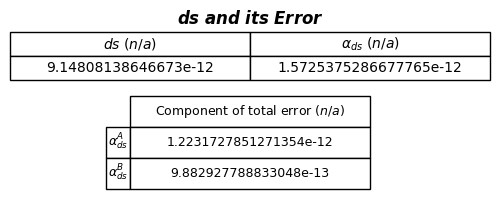

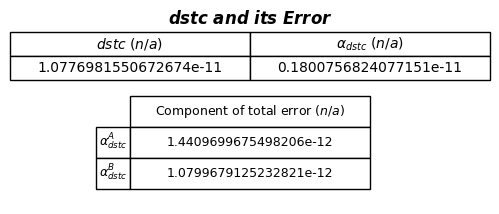

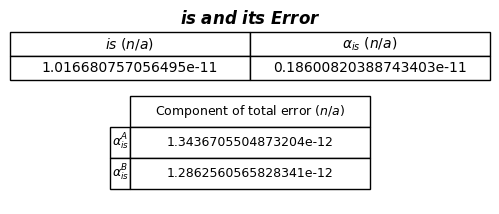

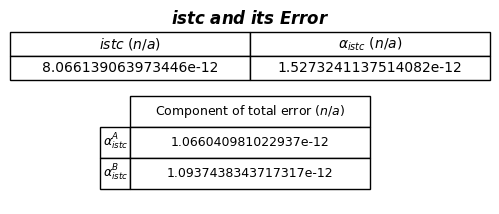

In [ ]:
def e(q,d):
    return (q*d)**2/(4*np.pi)

l1_finval = np.array([-1*l1_grad,l1_grad_err])
l2_finval = np.array([-1*l2_grad,l2_grad_err])
#print("l1", l1_finval)
#print("l2", l2_finval)


ds_finval = UDS([ds_charge,[ds_grad,ds_grad_err]]).display_func_err(e,show_comp=True,f_name= "{ds}")
is_finval = UDS([is_charge,[is_grad,is_grad_err]]).display_func_err(e,show_comp=True,f_name= "{is}")
dstc_finval = UDS([ds_charge,[dstc_grad,dstc_grad_err]]).display_func_err(e,show_comp=True,f_name= "{dstc}")
istc_finval = UDS([is_charge,[istc_grad,istc_grad_err]]).display_func_err(e,show_comp=True,f_name= "{istc}")




Result Table

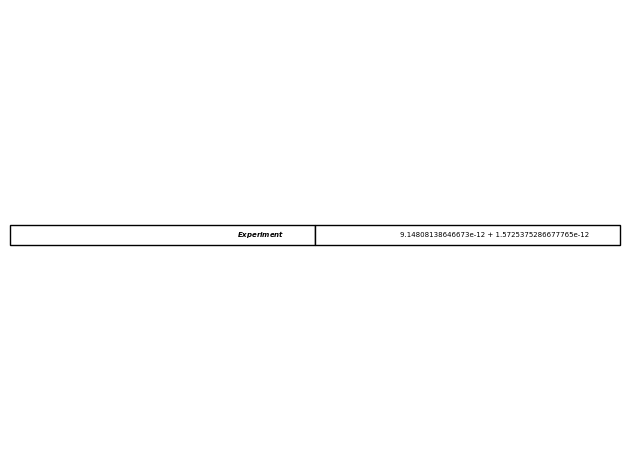

In [417]:
ds_finval = UDS([ds_charge,[ds_grad,ds_grad_err]]).functional_err(e)
dstc_finval = UDS([ds_charge,[dstc_grad,dstc_grad_err]]).functional_err(e)
is_finval = UDS([is_charge,[is_grad,is_grad_err]]).functional_err(e)
istc_finval = UDS([is_charge,[istc_grad,istc_grad_err]]).functional_err(e)

fig4 = plt.figure(4)
axt = fig4.gca()
fig4.patch.set_visible(False)
axt.axis('off')
axt.axis('tight')

table_contents = [["$\\mathbfit{Experiment}$","{0} + {1}".format(ds_finval[0],ds_finval[1])]]

plt.table(cellText = table_contents,loc = 'center')

fig4.tight_layout()
plt.show()
